In [1]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt

from scipy import stats
from scipy.stats import shapiro

from statsmodels.stats.contingency_tables import cochrans_q
from statsmodels.stats.contingency_tables import mcnemar
from itertools import combinations

from pycm import *
#pd.set_option("display.max_rows", 20)

In [2]:
def count_labels(value): #creating a dataframe containg the number of correct labels per prompt per model
    dic = {}
    prompts = ["Prompt 0", "Prompt 1", "Prompt 2", "Prompt 3", "Prompt 4", "Prompt 5", "Prompt 6", "Prompt 7"]

    for prompt in prompts:
        liste = []
        if prompt == "Prompt 0":
            an = prompt_0_checked["Anthropic"].value_counts().get(value,0)
            gw = prompt_0_checked["GWDG"].value_counts().get(value,0)
            op = prompt_0_checked["OpenAI"].value_counts().get(value,0)
        elif prompt == "Prompt 1":
            an = prompt_1_checked["Anthropic"].value_counts().get(value,0)
            gw = prompt_1_checked["GWDG"].value_counts().get(value,0)
            op = prompt_1_checked["OpenAI"].value_counts().get(value,0)
        elif prompt == "Prompt 2":
            an = prompt_2_checked["Anthropic"].value_counts().get(value,0)
            gw = prompt_2_checked["GWDG"].value_counts().get(value,0)
            op = prompt_2_checked["OpenAI"].value_counts().get(value,0)
        elif prompt == "Prompt 3":
            an = prompt_3_checked["Anthropic"].value_counts().get(value,0)
            gw = prompt_3_checked["GWDG"].value_counts().get(value,0)
            op = prompt_3_checked["OpenAI"].value_counts().get(value,0)
        elif prompt == "Prompt 4":
            an = prompt_4_checked["Anthropic"].value_counts().get(value,0)
            gw = prompt_4_checked["GWDG"].value_counts().get(value,0)
            op = prompt_4_checked["OpenAI"].value_counts().get(value,0)
        elif prompt == "Prompt 5":
            an = prompt_5_checked["Anthropic"].value_counts().get(value,0)
            gw = prompt_5_checked["GWDG"].value_counts().get(value,0)
            op = prompt_5_checked["OpenAI"].value_counts().get(value,0)
        elif prompt == "Prompt 6":
            an = prompt_6_checked["Anthropic"].value_counts().get(value,0)
            gw = prompt_6_checked["GWDG"].value_counts().get(value,0)
            op = prompt_6_checked["OpenAI"].value_counts().get(value,0)
        elif prompt == "Prompt 7":
            an = prompt_7_checked["Anthropic"].value_counts().get(value,0)
            gw = prompt_7_checked["GWDG"].value_counts().get(value,0)
            op = prompt_7_checked["OpenAI"].value_counts().get(value,0)

        liste.append(gw)
        liste.append(op)
        liste.append(an)
        dic[prompt] = liste

    df = pd.DataFrame.from_dict(orient="index", columns=["GWDG", "OpenAI", "Anthropic"], data=dic)

    return df


In [3]:
def result_in_percent (df):
    g = []
    o = []
    a = []
    for index, row in df.iterrows():
        g_p = round((row["GWDG"]/row["count"])*100, 2)
        o_p = round((row["OpenAI"]/row["count"])*100, 2)
        a_p = round((row["Anthropic"]/row["count"])*100, 2)
        g.append(str(float(g_p))+"%")
        o.append(str(float(o_p))+"%")
        a.append(str(float(a_p))+"%")

    df["GWDG in %"] = g
    df["Anthropic in %"] = a
    df["OpenAI in %"] = o
    return df


In [4]:
def detection_per_model(df):
    df_model = df.groupby("Source 1")[["GWDG", "Anthropic", "OpenAI"]].sum()
    df_model = pd.concat([df_model, paper_count_per_model], axis = 1)
    df_model = result_in_percent(df_model)
    return df_model

In [5]:
#determening the true positives rate per model
def combining_human_gen (df):
    #g, a, o = [], [], []
    #for index, row in df.iterrows():
    #    y
    
    g_h = df.loc[["ACL", "ACM", "IEEE", "Nature"],['GWDG']].sum(axis = 0).item()
    a_h = df.loc[["ACL", "ACM", "IEEE", "Nature"],['Anthropic']].sum(axis = 0).item()
    o_h = df.loc[["ACL", "ACM", "IEEE", "Nature"],['OpenAI']].sum(axis = 0).item()
    count_h = df.loc[["ACL", "ACM", "IEEE", "Nature"],['count']].sum(axis = 0).item()
    #g_p = df.loc[["ACL", "ACM", "IEEE", "Nature"],['GWDG']].sum(axis = 0)
    #df.loc["human-written"] = [g,a,o,count, None, None, None]


    g = df.loc[["claude-haiku-4-5-20251001", "deepseek-v4-flash", "gpt-5.6"],['GWDG']].sum(axis = 0).item()
    a = df.loc[["claude-haiku-4-5-20251001", "deepseek-v4-flash", "gpt-5.6"],['Anthropic']].sum(axis = 0).item()
    o = df.loc[["claude-haiku-4-5-20251001", "deepseek-v4-flash", "gpt-5.6"],['OpenAI']].sum(axis = 0).item()
    count = df.loc[["claude-haiku-4-5-20251001", "deepseek-v4-flash", "gpt-5.6"],['count']].sum(axis = 0).item()

    
    df.loc["human-written"] = [g_h, a_h, o_h, count_h, None, None, None]
    df.loc["generated"] = [int(g),int(a),int(o),int(count), None, None, None]
    df = result_in_percent(df)
        
    return df




In [6]:
def check_if_correct_per_model(current_df):
    checked = {}
    file = {}

    prompts = ["Prompt 0", "Prompt 1", "Prompt 2", "Prompt 3", "Prompt 4", "Prompt 5", "Prompt 6", "Prompt 7"]
    for prompt in prompts:
        liste = []

        for index, row in current_df.iterrows():
            if row[prompt] == row["Correct"]:
                liste.append(True)
            else:
                liste.append(False)
            file[prompt] = liste
            checked.update(file)

    checked_df = pd.DataFrame.from_dict(checked)

    return checked_df

In [7]:
def calculate_mcnemar(data, conditions):
    n_conditions = len(conditions)
    alpha_corrected = 0.05 / len(list(combinations(range(n_conditions), 2)))

    # Assuming 'data' is a pandas DataFrame with columns named after the conditions
    # and values of 0 or 1

    # Create a list to store results
    results = []

    # Perform pairwise McNemar tests for all combinations
    for i, j in combinations(range(n_conditions), 2):
        # Extract the two columns as pandas Series
        col_i = data[conditions[i]]
        col_j = data[conditions[j]]
        
        # Create the 2x2 contingency table using pandas operations
        pair_table = pd.DataFrame([
            [((col_i == 1) & (col_j == 1)).sum(),
            ((col_i == 1) & (col_j == 0)).sum()],
            [((col_i == 0) & (col_j == 1)).sum(),
            ((col_i == 0) & (col_j == 0)).sum()]
        ])
        
        # Convert to numpy array for mcnemar function
        pair_result = mcnemar(pair_table.values, exact=False, correction=True)
        
        # Determine significance
        sig = "significant" if pair_result.pvalue < alpha_corrected else "not significant"
        
        # Store results
        results.append({
            'Condition 1': conditions[i],
            'Condition 2': conditions[j],
            'Both 1': int(((col_i == 1) & (col_j == 1)).sum()),
            'Only 1': int(((col_i == 1) & (col_j == 0)).sum()),
            'Only 2': int(((col_i == 0) & (col_j == 1)).sum()),
            'Both 0': int(((col_i == 0) & (col_j == 0)).sum()),
            'p-value': round(pair_result.pvalue, 4),
            'Significant': sig,
            'Alpha': round(alpha_corrected, 4)
        })

    # Create a DataFrame from the results
    results_df = pd.DataFrame(results)

    # Display the table
    #print(results_df.to_string(index=False))
    return results_df

In [8]:
def calculate_cochrans_q (data, conditions):
    result = cochrans_q(data) # rows = individuals, columns = conditions
    print(f"Q statistic: {result.statistic:.3f}")
    print(f"p-value: {result.pvalue:.4f}")

    n, k = data.shape
    W = result.statistic / (n * (k - 1))
    print(f"Kendall's W: {W:.3f}")

    if result.pvalue <= 0.05:
        df = calculate_mcnemar(data, conditions)  
        return df
    else: print("Mcnemar was not calculated")
    

In [9]:
gwdg_df = pd.read_excel("Preprocessed_GWDG_Detection.xlsx", index_col=0)
openai_df = pd.read_excel("Preprocessed_OpenAI_Detection.xlsx", index_col=0)
anthropic_df = pd.read_excel("Preprocessed_Anthropic_Detection.xlsx", index_col=0)
key = pd.read_excel("Key.xlsx")
comparison = pd.read_excel("Checked_Comparison_Method.xlsx", index_col=0)
comparison2 = pd.read_excel("Comparison_Method_2_Preprocessed.xlsx")
#comparison = comparison.drop('Unnamed: 0.1', axis=1)
#comparison.columns = ["Unnamed: 0", "Comparison"]
prompt_0_checked = pd.read_csv("Checked_Prompt_0_Df.csv", index_col=0)
prompt_1_checked = pd.read_csv("Checked_Prompt_1_Df.csv", index_col=0)
prompt_2_checked = pd.read_csv("Checked_Prompt_2_Df.csv", index_col=0)
prompt_3_checked = pd.read_csv("Checked_Prompt_3_Df.csv", index_col=0)
prompt_4_checked = pd.read_csv("Checked_Prompt_4_Df.csv", index_col=0)
prompt_5_checked = pd.read_csv("Checked_Prompt_5_Df.csv", index_col=0)
prompt_6_checked = pd.read_csv("Checked_Prompt_6_Df.csv", index_col=0)
prompt_7_checked = pd.read_csv("Checked_Prompt_7_Df.csv", index_col=0)

complete_key = pd.read_excel("Complete_Key.xlsx", index_col=0)
complete_key["File"] = complete_key["new"].astype(str) + ".md"
#complete_key = complete_key.sort_values(by='new').reset_index()
#complete_key = complete_key.reset_index()
#complete_key = complete_key.drop(columns="Unnamed: 0")
kom_key = pd.read_excel("Kom_Key.xlsx", index_col=0)
complete = pd.read_excel("Detection_per_Source/Complete.xlsx", index_col=[0,1])

In [10]:
#reading the csv
prompt_0 = pd.read_csv("Normalized_Prompts/Prompt_0_Normalized.csv", index_col=0)
prompt_1 = pd.read_csv("Normalized_Prompts/Prompt_1_Normalized.csv", index_col=0)
prompt_2 = pd.read_csv("Normalized_Prompts/Prompt_2_Normalized.csv", index_col=0)
prompt_3 = pd.read_csv("Normalized_Prompts/Prompt_3_Normalized.csv", index_col=0)
prompt_4 = pd.read_csv("Normalized_Prompts/Prompt_4_Normalized.csv", index_col=0)
prompt_5 = pd.read_csv("Normalized_Prompts/Prompt_5_Normalized.csv", index_col=0)
prompt_6 = pd.read_csv("Normalized_Prompts/Prompt_6_Normalized.csv", index_col=0)
prompt_7 = pd.read_csv("Normalized_Prompts/Prompt_7_Normalized.csv", index_col=0)

In [11]:
df = count_labels(True)

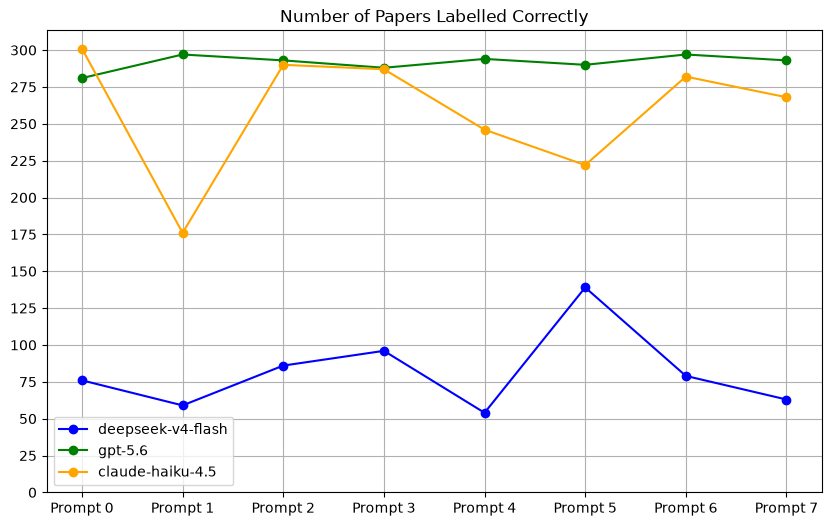

In [165]:
fig = df.plot(
    y=["GWDG", "OpenAI", "Anthropic"], 
    kind="line", 
    title="Number of Papers Labelled Correctly", 
    legend=True, 
    color=["Blue", "Green", "Orange"], 
    use_index=True,
    grid= True,
    label=["deepseek-v4-flash", "gpt-5.6", "claude-haiku-4.5"],
    yticks=range(0, 325, 25),
    marker='o',
    figsize=(10, 6)
    )

In [12]:
prompt_0_checked = pd.merge(prompt_0_checked, complete_key, on="File", how="left")
prompt_1_checked = pd.merge(prompt_1_checked, complete_key, on="File", how="left")
prompt_2_checked = pd.merge(prompt_2_checked, complete_key, on="File", how="left")
prompt_3_checked = pd.merge(prompt_3_checked, complete_key, on="File", how="left")
prompt_4_checked = pd.merge(prompt_4_checked, complete_key, on="File", how="left")
prompt_5_checked = pd.merge(prompt_5_checked, complete_key, on="File", how="left")
prompt_6_checked = pd.merge(prompt_6_checked, complete_key, on="File", how="left")
prompt_7_checked = pd.merge(prompt_7_checked, complete_key, on="File", how="left")

prompt_0_checked.drop(["new", "old", "Filenumber", "anon", "doi", "date", "Journal 2"],axis=1, inplace=True)
prompt_1_checked.drop(["new", "old", "Filenumber", "anon", "doi", "date", "Journal 2"],axis=1, inplace=True)
prompt_2_checked.drop(["new", "old", "Filenumber", "anon", "doi", "date", "Journal 2"],axis=1, inplace=True)
prompt_3_checked.drop(["new", "old", "Filenumber", "anon", "doi", "date", "Journal 2"],axis=1, inplace=True)
prompt_4_checked.drop(["new", "old", "Filenumber", "anon", "doi", "date", "Journal 2"],axis=1, inplace=True)
prompt_5_checked.drop(["new", "old", "Filenumber", "anon", "doi", "date", "Journal 2"],axis=1, inplace=True)
prompt_6_checked.drop(["new", "old", "Filenumber", "anon", "doi", "date", "Journal 2"],axis=1, inplace=True)
prompt_7_checked.drop(["new", "old", "Filenumber", "anon", "doi", "date", "Journal 2"],axis=1, inplace=True)

In [13]:
prompt_0 = pd.merge(prompt_0, complete_key, on="File", how="left")
prompt_1 = pd.merge(prompt_1, complete_key, on="File", how="left")
prompt_2 = pd.merge(prompt_2, complete_key, on="File", how="left")
prompt_3 = pd.merge(prompt_3, complete_key, on="File", how="left")
prompt_4 = pd.merge(prompt_4, complete_key, on="File", how="left")
prompt_5 = pd.merge(prompt_5, complete_key, on="File", how="left")
prompt_6 = pd.merge(prompt_6, complete_key, on="File", how="left")
prompt_7 = pd.merge(prompt_7, complete_key, on="File", how="left")

prompt_0.drop(["new", "old", "Filenumber", "anon", "doi", "date", "Journal 2"],axis=1, inplace=True)
prompt_1.drop(["new", "old", "Filenumber", "anon", "doi", "date", "Journal 2"],axis=1, inplace=True)
prompt_2.drop(["new", "old", "Filenumber", "anon", "doi", "date", "Journal 2"],axis=1, inplace=True)
prompt_3.drop(["new", "old", "Filenumber", "anon", "doi", "date", "Journal 2"],axis=1, inplace=True)
prompt_4.drop(["new", "old", "Filenumber", "anon", "doi", "date", "Journal 2"],axis=1, inplace=True)
prompt_5.drop(["new", "old", "Filenumber", "anon", "doi", "date", "Journal 2"],axis=1, inplace=True)
prompt_6.drop(["new", "old", "Filenumber", "anon", "doi", "date", "Journal 2"],axis=1, inplace=True)
prompt_7.drop(["new", "old", "Filenumber", "anon", "doi", "date", "Journal 2"],axis=1, inplace=True)

In [14]:
paper_count_per_model = complete_key["Source 1"].value_counts().to_frame()
p_0 = detection_per_model(prompt_0_checked)
p_1 = detection_per_model(prompt_1_checked)
p_2 = detection_per_model(prompt_2_checked)
p_3 = detection_per_model(prompt_3_checked)
p_4 = detection_per_model(prompt_4_checked)
p_5 = detection_per_model(prompt_5_checked)
p_6 = detection_per_model(prompt_6_checked)
p_7 = detection_per_model(prompt_7_checked)

In [15]:
p_0 = combining_human_gen(p_0)
p_1 = combining_human_gen(p_1)
p_2 = combining_human_gen(p_2)
p_3 = combining_human_gen(p_3)
p_4 = combining_human_gen(p_4)
p_5 = combining_human_gen(p_5)
p_6 = combining_human_gen(p_6)
p_7 = combining_human_gen(p_7)

In [ ]:
#is already saved
comparison = pd.merge(comparison, complete_key, on="File", how="left")
comparison.drop(["new", "old", "Filenumber", "anon", "doi", "date", "Journal 2"],axis=1, inplace=True)
comparison.to_excel("Checked_Comparison_Method.xlsx")

In [16]:
com_model = comparison.groupby("Source 1")["Checked"].sum()
com_model = pd.concat([com_model, paper_count_per_model], axis = 1)
com_model

,Checked,count
Source 1,,
ACL,16,44
ACM,37,46
IEEE,150,162
Nature,23,23
Student,10,11
claude-haiku-4-5-20251001,8,8
deepseek-v4-flash,19,19
gpt-5.6,28,28


In [17]:
check_h = com_model.loc[["ACL", "ACM", "IEEE", "Nature"],['Checked']].sum(axis = 0).item()
check = com_model.loc[["claude-haiku-4-5-20251001", "deepseek-v4-flash", "gpt-5.6"],['Checked']].sum(axis = 0).item()
count_h = com_model.loc[["ACL", "ACM", "IEEE", "Nature"],['count']].sum(axis = 0).item()
count = com_model.loc[["claude-haiku-4-5-20251001", "deepseek-v4-flash", "gpt-5.6"],['count']].sum(axis = 0).item()
    
com_model.loc["human-written"] = [check_h, count_h]
com_model.loc["generated"] = [int(check),int(count)]

saving the dataframes in files

In [89]:
p_0.to_excel("Detection_per_Source/prompt_0.xlsx")
p_1.to_excel("Detection_per_Source/prompt_1.xlsx")
p_2.to_excel("Detection_per_Source/prompt_2.xlsx")
p_3.to_excel("Detection_per_Source/prompt_3.xlsx")
p_4.to_excel("Detection_per_Source/prompt_4.xlsx")
p_5.to_excel("Detection_per_Source/prompt_5.xlsx")
p_6.to_excel("Detection_per_Source/prompt_6.xlsx")
p_7.to_excel("Detection_per_Source/prompt_7.xlsx")

#saving everything in the same excel map but each with its own sheet
with pd.ExcelWriter("Detection_per_Source/Complete_in_Sheets.xlsx") as writer:
    p_0.to_excel(writer, sheet_name="Prompt 0")
    p_1.to_excel(writer, sheet_name="Prompt 1")
    p_2.to_excel(writer, sheet_name="Prompt 2")
    p_3.to_excel(writer, sheet_name="Prompt 3")
    p_4.to_excel(writer, sheet_name="Prompt 4")
    p_5.to_excel(writer, sheet_name="Prompt 5")
    p_6.to_excel(writer, sheet_name="Prompt 6")
    p_7.to_excel(writer, sheet_name="Prompt 7")
    com_model.to_excel(writer, sheet_name = "Comparison Prompt")
    
                   

In [90]:
#saving all in one excel file
ges = pd.concat([p_0, p_1, p_2, p_3, p_4, p_5, p_6, p_7, com_model], axis=0, keys=["Prompt 0", "Prompt 1", "Prompt 2", "Prompt 3", "Prompt 4", "Prompt 5", "Prompt 6", "Prompt 7", "Comparison Prompt"])
ges.to_excel("Detection_per_Source/Complete.xlsx")


Adding a column containing the year of publishing for the papers

In [18]:
years = []
for index, row in complete_key.iterrows():
    if row["date"]:
        ye = str(row["date"])[:4]
    else:
        ye = "NaN"
    years.append(ye)
complete_key["Jahr"] = years

In [19]:
for index, row in complete_key.iterrows(): #setting the Jahr-value for ACL entries to 2026
    if row["Source 1"] == "ACL":
        #row["Jahr"] = 2026
        complete_key.at[index,'Jahr'] = str(2026)

C:\Users\denni\AppData\Local\Temp\ipykernel_12704\1204159529.py:1: ChainedAssignmentError: A value is being set on a copy of a DataFrame or Series through chained assignment.
Such chained assignment never works to update the original DataFrame or Series, because the intermediate object on which we are setting values always behaves as a copy (due to Copy-on-Write).

Try using '.loc[row_indexer, col_indexer] = value' instead, to perform the assignment in a single step.

See the documentation for a more detailed explanation: https://pandas.pydata.org/pandas-docs/stable/user_guide/copy_on_write.html#chained-assignment
  complete_key[complete_key["Jahr"] != "nan"]["Jahr"]= complete_key[complete_key["Jahr"] != "nan"]["Jahr"].astype(int)


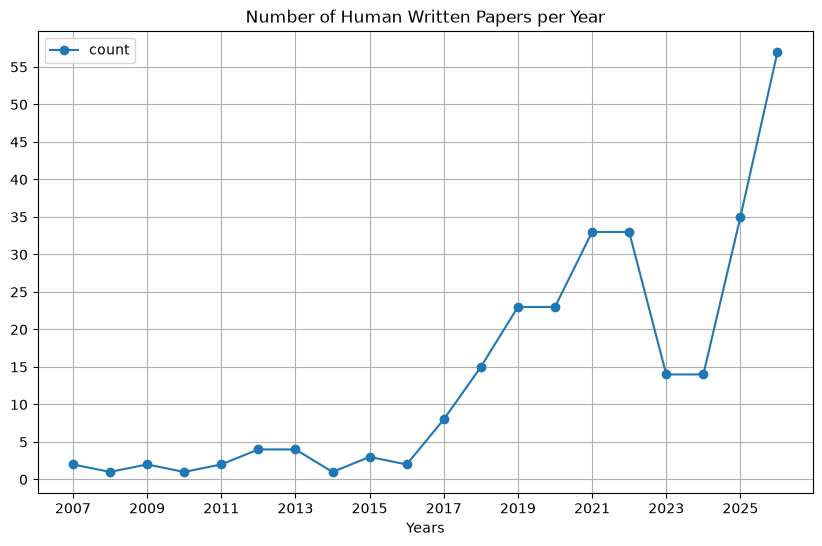

In [20]:
complete_key[complete_key["Jahr"] != "nan"]["Jahr"]= complete_key[complete_key["Jahr"] != "nan"]["Jahr"].astype(int)
data = complete_key[complete_key["Jahr"] != "nan"]["Jahr"].value_counts().sort_index()
fig = data.plot(
    y=[2007, 2008, 2009, 2010, 2011, 2012, 2013, 2014, 2015, 2016, 2017, 2018, 2019, 2020, 2021, 2022, 2023, 2024, 2025, 2026], 
    kind="line", 
    title="Number of Human Written Papers per Year", 
    legend=True, 
    #color=["Blue", "Green", "Orange"], 
    use_index=True,
    grid= True,
    yticks=range(0, 60, 5),
    xticks=range(0, 20, 2),
    marker='o',
    figsize=(10, 6),
    xlabel="Years"
    )

In [21]:
complete_key["Jahr"].value_counts().head(20)

Jahr
nan     64
2026    57
2025    35
2021    33
2022    33
2020    23
2019    23
2018    15
2023    14
2024    14
2017     8
2012     4
2013     4
2015     3
2009     2
2011     2
2007     2
2016     2
2014     1
2010     1
Name: count, dtype: int64

In [22]:
df_t = count_labels(True)
df_f = count_labels(False)

#creating dataframes for every model with every prompt and the number of correct and wrong labels
gw = pd.concat([df_t["GWDG"], df_f["GWDG"]], axis = 1)
gw.columns = ["Correct Labels", "Wrong Labels"]
an = pd.concat([df_t["Anthropic"], df_f["Anthropic"]], axis = 1)
an.columns = ["Correct Labels", "Wrong Labels"]
op = pd.concat([df_t["OpenAI"], df_f["OpenAI"]], axis = 1)
op.columns = ["Correct Labels", "Wrong Labels"]

#creating dataframes for every prompt with the number of correct and wrong labels per model
p0 = pd.concat([df_t.loc["Prompt 0"], df_f.loc["Prompt 0"]], axis=1, keys=["Correct Labels", "Wrong Labels"])
p1 = pd.concat([df_t.loc["Prompt 1"], df_f.loc["Prompt 1"]], axis=1, keys=["Correct Labels", "Wrong Labels"])
p2 = pd.concat([df_t.loc["Prompt 2"], df_f.loc["Prompt 2"]], axis=1, keys=["Correct Labels", "Wrong Labels"])
p3 = pd.concat([df_t.loc["Prompt 3"], df_f.loc["Prompt 3"]], axis=1, keys=["Correct Labels", "Wrong Labels"])
p4 = pd.concat([df_t.loc["Prompt 4"], df_f.loc["Prompt 4"]], axis=1, keys=["Correct Labels", "Wrong Labels"])
p5 = pd.concat([df_t.loc["Prompt 5"], df_f.loc["Prompt 5"]], axis=1, keys=["Correct Labels", "Wrong Labels"])
p6 = pd.concat([df_t.loc["Prompt 6"], df_f.loc["Prompt 6"]], axis=1, keys=["Correct Labels", "Wrong Labels"])
p7 = pd.concat([df_t.loc["Prompt 7"], df_f.loc["Prompt 7"]], axis=1, keys=["Correct Labels", "Wrong Labels"])


In [23]:
gwdg = check_if_correct_per_model(gwdg_df)
openai = check_if_correct_per_model(openai_df)
anthropic = check_if_correct_per_model(anthropic_df)

In [114]:
calculate_cochrans_q(gwdg, gwdg.columns)

Q statistic: 176.165
p-value: 0.0000
Kendall's W: 0.074


,Condition 1,Condition 2,Both 1,Only 1,Only 2,Both 0,p-value,Significant,Alpha
0,Prompt 0,Prompt 1,55,21,4,261,0.0014,significant,0.0018
1,Prompt 0,Prompt 2,55,21,31,234,0.2120,not significant,0.0018
2,Prompt 0,Prompt 3,58,18,38,227,0.0111,not significant,0.0018
3,Prompt 0,Prompt 4,54,22,0,265,0.0000,significant,0.0018
4,Prompt 0,Prompt 5,48,28,91,174,0.0000,significant,0.0018
5,Prompt 0,Prompt 6,56,20,23,242,0.7604,not significant,0.0018
6,Prompt 0,Prompt 7,53,23,10,255,0.0367,not significant,0.0018
7,Prompt 1,Prompt 2,51,8,35,247,0.0001,significant,0.0018
8,Prompt 1,Prompt 3,55,4,41,241,0.0000,significant,0.0018
9,Prompt 1,Prompt 4,54,5,0,282,0.0736,not significant,0.0018


In [111]:
pd.set_option("display.max_rows", None)

In [112]:
calculate_cochrans_q(openai, openai.columns)

Q statistic: 36.442
p-value: 0.0000
Kendall's W: 0.015


,Condition 1,Condition 2,Both 1,Only 1,Only 2,Both 0,p-value,Significant,Alpha
0,Prompt 0,Prompt 1,280,1,17,43,0.0004,significant,0.0018
1,Prompt 0,Prompt 2,281,0,12,48,0.0015,significant,0.0018
2,Prompt 0,Prompt 3,278,3,10,50,0.0961,not significant,0.0018
3,Prompt 0,Prompt 4,280,1,14,46,0.0019,not significant,0.0018
4,Prompt 0,Prompt 5,279,2,11,49,0.0265,not significant,0.0018
5,Prompt 0,Prompt 6,281,0,16,44,0.0002,significant,0.0018
6,Prompt 0,Prompt 7,279,2,14,46,0.0060,not significant,0.0018
7,Prompt 1,Prompt 2,290,7,3,41,0.3428,not significant,0.0018
8,Prompt 1,Prompt 3,285,12,3,41,0.0389,not significant,0.0018
9,Prompt 1,Prompt 4,292,5,2,42,0.4497,not significant,0.0018


In [113]:
calculate_cochrans_q(anthropic, anthropic.columns)

Q statistic: 301.535
p-value: 0.0000
Kendall's W: 0.126


,Condition 1,Condition 2,Both 1,Only 1,Only 2,Both 0,p-value,Significant,Alpha
0,Prompt 0,Prompt 1,155,146,21,19,0.0000,significant,0.0018
1,Prompt 0,Prompt 2,284,17,6,34,0.0371,not significant,0.0018
2,Prompt 0,Prompt 3,280,21,7,33,0.0140,not significant,0.0018
3,Prompt 0,Prompt 4,231,70,15,25,0.0000,significant,0.0018
4,Prompt 0,Prompt 5,217,84,5,35,0.0000,significant,0.0018
5,Prompt 0,Prompt 6,277,24,5,35,0.0008,significant,0.0018
6,Prompt 0,Prompt 7,264,37,4,36,0.0000,significant,0.0018
7,Prompt 1,Prompt 2,139,37,151,14,0.0000,significant,0.0018
8,Prompt 1,Prompt 3,139,37,148,17,0.0000,significant,0.0018
9,Prompt 1,Prompt 4,157,19,89,76,0.0000,significant,0.0018


In [24]:
#accuracy per prompt per modell
df = count_labels(True)
dic = {}
for index, row in df.iterrows():
    g = round((row["GWDG"]/341)*100, 2)
    o = round((row["OpenAI"]/341)*100, 2)
    a = round((row["Anthropic"]/341)*100, 2)
    dic[index] = [str(g)+"%", str(o)+"%", str(a)+"%"]

df_in_percent = pd.DataFrame.from_dict(dic).transpose()
df_in_percent.columns = ["GWDG", "OpenAI", "Anthropic"]

In [25]:
df_in_percent

,GWDG,OpenAI,Anthropic
Prompt 0,22.29%,82.4%,88.27%
Prompt 1,17.3%,87.1%,51.61%
Prompt 2,25.22%,85.92%,85.04%
Prompt 3,28.15%,84.46%,84.16%
Prompt 4,15.84%,86.22%,72.14%
Prompt 5,40.76%,85.04%,65.1%
Prompt 6,23.17%,87.1%,82.7%
Prompt 7,18.48%,85.92%,78.59%


In [167]:
complete.loc["Prompt 0"].at["human-written", "Anthropic"]

np.float64(265.0)

In [26]:
def exact_label (name):

    p = {}
    ges = {}
    prompts = ["Prompt 0", "Prompt 1", "Prompt 2", "Prompt 3", "Prompt 4", "Prompt 5", "Prompt 6", "Prompt 7"]
    for prompt in prompts:
        h = complete.loc[prompt].at["human-written", name]
        g = complete.loc[prompt].at["generated", name]
        
        p[prompt] = [int(h), int(g)]
  
    ges.update(p)
    df = pd.DataFrame.from_dict(ges)
    df.index = ["human-written", "generated"]
    return df

In [27]:
a = exact_label("Anthropic") #counts the number of label
g = exact_label("GWDG")
o = exact_label("OpenAI")

In [28]:
g

,Prompt 0,Prompt 1,Prompt 2,Prompt 3,Prompt 4,Prompt 5,Prompt 6,Prompt 7
human-written,19,4,34,42,0,95,26,10
generated,55,55,50,51,54,36,50,52


In [29]:
df = pd.concat([g, o, a], axis = 0)
df = df.transpose()
df.columns = ["human-written - deepseek-v4-flash", "generated - deepseek-v4-flash", "human-written - gpt-5.6", "generated - gpt-5.6", "human-written - claude-haiku-4.5", "generated - claude-haiku-4.5"]

In [191]:
count_labels(True)

,GWDG,OpenAI,Anthropic
Prompt 0,76,281,301
Prompt 1,59,297,176
Prompt 2,86,293,290
Prompt 3,96,288,287
Prompt 4,54,294,246
Prompt 5,139,290,222
Prompt 6,79,297,282
Prompt 7,63,293,268


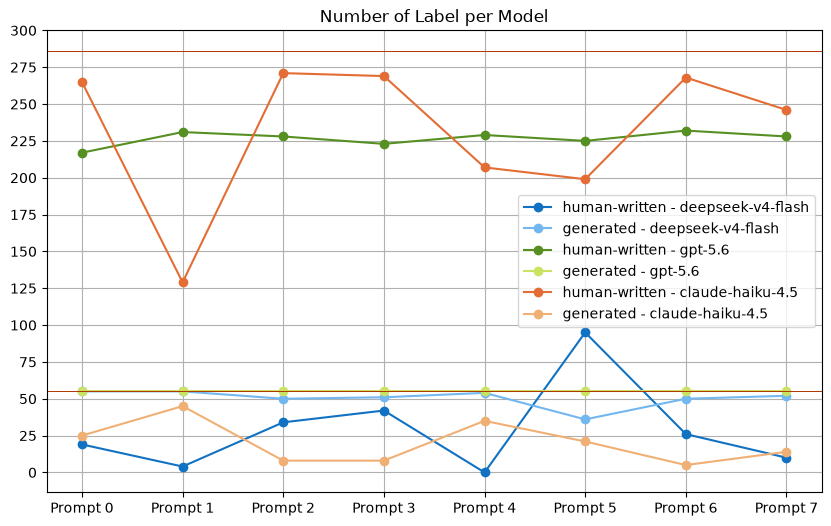

In [209]:
fig = df.plot(
    y=["human-written - deepseek-v4-flash", "generated - deepseek-v4-flash", "human-written - gpt-5.6", "generated - gpt-5.6", "human-written - claude-haiku-4.5", "generated - claude-haiku-4.5"], 
    kind="line", 
    title="Number of Label per Model", 
    legend=True, 
    color=["#1171C2", "#73B7F0", "#568F22", "#CAE362", "#E36D34", "#F0B075"], 
    use_index=True,
    grid= True,
    label=["human-written - deepseek-v4-flash", "generated - deepseek-v4-flash", "human-written - gpt-5.6", "generated - gpt-5.6", "human-written - claude-haiku-4.5", "generated - claude-haiku-4.5"],
    yticks=range(0, 325, 25),
    marker='o',
    figsize=(10, 6)
    )
plt.axhline(y=55, c="#B03400", lw=0.7)
plt.axhline(y=286, c="#B03400", lw=0.7)

In [ ]:
#adding the source to the second comparison method
comparison2 = pd.concat([comparison2, complete_key["Source 1"]], axis=1)
comparison2.to_excel("Comparison_Method_2_Preprocessed.xlsx", index=False)

In [30]:
comparison_m = comparison2.groupby("Source 1")["Checked"].sum()
comparison_m = pd.concat([comparison_m, paper_count_per_model], axis = 1)
comparison_m

,Checked,count
Source 1,,
ACL,33,44
ACM,36,46
IEEE,117,162
Nature,14,23
Student,11,11
claude-haiku-4-5-20251001,5,8
deepseek-v4-flash,15,19
gpt-5.6,22,28


In [31]:
check_h = comparison_m.loc[["ACL", "ACM", "IEEE", "Nature"],['Checked']].sum(axis = 0).item()
check = comparison_m.loc[["claude-haiku-4-5-20251001", "deepseek-v4-flash", "gpt-5.6"],['Checked']].sum(axis = 0).item()
count_h = comparison_m.loc[["ACL", "ACM", "IEEE", "Nature"],['count']].sum(axis = 0).item()
count = comparison_m.loc[["claude-haiku-4-5-20251001", "deepseek-v4-flash", "gpt-5.6"],['count']].sum(axis = 0).item()
    
comparison_m.loc["human-written"] = [check_h, count_h]
comparison_m.loc["generated"] = [int(check),int(count)]

In [107]:
comparison_m.to_excel("Comparison_Method_2_counts.xlsx", index=False)

In [32]:
comparison_m

,Checked,count
Source 1,,
ACL,33,44
ACM,36,46
IEEE,117,162
Nature,14,23
Student,11,11
claude-haiku-4-5-20251001,5,8
deepseek-v4-flash,15,19
gpt-5.6,22,28
human-written,200,275


In [33]:
df_in_percent

,GWDG,OpenAI,Anthropic
Prompt 0,22.29%,82.4%,88.27%
Prompt 1,17.3%,87.1%,51.61%
Prompt 2,25.22%,85.92%,85.04%
Prompt 3,28.15%,84.46%,84.16%
Prompt 4,15.84%,86.22%,72.14%
Prompt 5,40.76%,85.04%,65.1%
Prompt 6,23.17%,87.1%,82.7%
Prompt 7,18.48%,85.92%,78.59%


In [49]:
prompt_0_checked.value_counts("Source 1")

Source 1
IEEE                         162
ACM                           46
ACL                           44
gpt-5.6                       28
Nature                        23
deepseek-v4-flash             19
Student                       11
claude-haiku-4-5-20251001      8
Name: count, dtype: int64

In [96]:
complete.loc["Prompt 1"]["GWDG in %"].to_list()

['0.0%',
 '0.0%',
 '1.23%',
 '8.7%',
 '0.0%',
 '100.0%',
 '100.0%',
 '100.0%',
 '1.45%',
 '100.0%']

In [131]:
prompts = ["Prompt 0", "Prompt 1", "Prompt 2", "Prompt 3", "Prompt 4", "Prompt 5", "Prompt 6", "Prompt 7"]
#models = ["GWDG in %", "Anthropic in %", "OpenAI in %"]


p_dic = {}
for prompt in prompts:
    dic = {}
    liste_g = complete.loc[prompt]["GWDG in %"].to_list()
    liste_a = complete.loc[prompt]["Anthropic in %"].to_list()
    liste_o = complete.loc[prompt]["OpenAI in %"].to_list() 
    dic["GWDG"] = liste_g[:-2]
    dic["Anthropic"] = liste_a[:-2]
    dic["OpenAI"] = liste_o[:-2]
    

    p_dic[prompt] = dic

In [132]:
prompt_source_0 = pd.DataFrame.from_dict(p_dic["Prompt 0"])
prompt_source_0.index = ["ACL", "ACM", "IEEE", "Nature", "Student", "claude-haiku-4.5", "deepseek-v4-flash", "gpt-5.6"]

prompt_source_1 = pd.DataFrame.from_dict(p_dic["Prompt 1"])
prompt_source_1.index = ["ACL", "ACM", "IEEE", "Nature", "Student", "claude-haiku-4.5", "deepseek-v4-flash", "gpt-5.6"]

prompt_source_2 = pd.DataFrame.from_dict(p_dic["Prompt 2"])
prompt_source_2.index = ["ACL", "ACM", "IEEE", "Nature", "Student", "claude-haiku-4.5", "deepseek-v4-flash", "gpt-5.6"]

prompt_source_3 = pd.DataFrame.from_dict(p_dic["Prompt 3"])
prompt_source_3.index = ["ACL", "ACM", "IEEE", "Nature", "Student", "claude-haiku-4.5", "deepseek-v4-flash", "gpt-5.6"]

prompt_source_4 = pd.DataFrame.from_dict(p_dic["Prompt 4"])
prompt_source_4.index = ["ACL", "ACM", "IEEE", "Nature", "Student", "claude-haiku-4.5", "deepseek-v4-flash", "gpt-5.6"]

prompt_source_5 = pd.DataFrame.from_dict(p_dic["Prompt 5"])
prompt_source_5.index = ["ACL", "ACM", "IEEE", "Nature", "Student", "claude-haiku-4.5", "deepseek-v4-flash", "gpt-5.6"]

prompt_source_6 = pd.DataFrame.from_dict(p_dic["Prompt 6"])
prompt_source_6.index = ["ACL", "ACM", "IEEE", "Nature", "Student", "claude-haiku-4.5", "deepseek-v4-flash", "gpt-5.6"]

prompt_source_7 = pd.DataFrame.from_dict(p_dic["Prompt 7"])
prompt_source_7.index = ["ACL", "ACM", "IEEE", "Nature", "Student", "claude-haiku-4.5", "deepseek-v4-flash", "gpt-5.6"]

In [133]:
prompt_source_gwdg = pd.concat([prompt_source_0["GWDG"], prompt_source_1["GWDG"], prompt_source_2["GWDG"], prompt_source_3["GWDG"], prompt_source_4["GWDG"], prompt_source_5["GWDG"], prompt_source_6["GWDG"], prompt_source_7["GWDG"]], axis=1)
prompt_source_gwdg.columns=["Prompt 0", "Prompt 1", "Prompt 2", "Prompt 3", "Prompt 4", "Prompt 5", "Prompt 6", "Prompt 7"]

prompt_source_anthropic = pd.concat([prompt_source_0["Anthropic"], prompt_source_1["Anthropic"], prompt_source_2["Anthropic"], prompt_source_3["Anthropic"], prompt_source_4["Anthropic"], prompt_source_5["Anthropic"], prompt_source_6["Anthropic"], prompt_source_7["Anthropic"]], axis=1)
prompt_source_anthropic.columns=["Prompt 0", "Prompt 1", "Prompt 2", "Prompt 3", "Prompt 4", "Prompt 5", "Prompt 6", "Prompt 7"]

prompt_source_openai = pd.concat([prompt_source_0["OpenAI"], prompt_source_1["OpenAI"], prompt_source_2["OpenAI"], prompt_source_3["OpenAI"], prompt_source_4["OpenAI"], prompt_source_5["OpenAI"], prompt_source_6["OpenAI"], prompt_source_7["OpenAI"]], axis=1)
prompt_source_openai.columns=["Prompt 0", "Prompt 1", "Prompt 2", "Prompt 3", "Prompt 4", "Prompt 5", "Prompt 6", "Prompt 7"]

prompt_source_anthropic = prompt_source_anthropic.transpose()
prompt_source_gwdg = prompt_source_gwdg.transpose()
prompt_source_openai = prompt_source_openai.transpose()

In [134]:
columns = ["ACL", "ACM", "IEEE", "Nature", "Student", "claude-haiku-4.5", "deepseek-v4-flash", "gpt-5.6"]
for index, row in prompt_source_anthropic.iterrows():
    for column in columns:
        entrie = row[column]
        prompt_source_anthropic.at[index, column] = entrie[:-1]

for index, row in prompt_source_gwdg.iterrows():
    for column in columns:
        entrie = row[column]
        prompt_source_gwdg.at[index, column] = entrie[:-1]

for index, row in prompt_source_openai.iterrows():
    for column in columns:
        entrie = row[column]
        prompt_source_openai.at[index, column] = entrie[:-1]

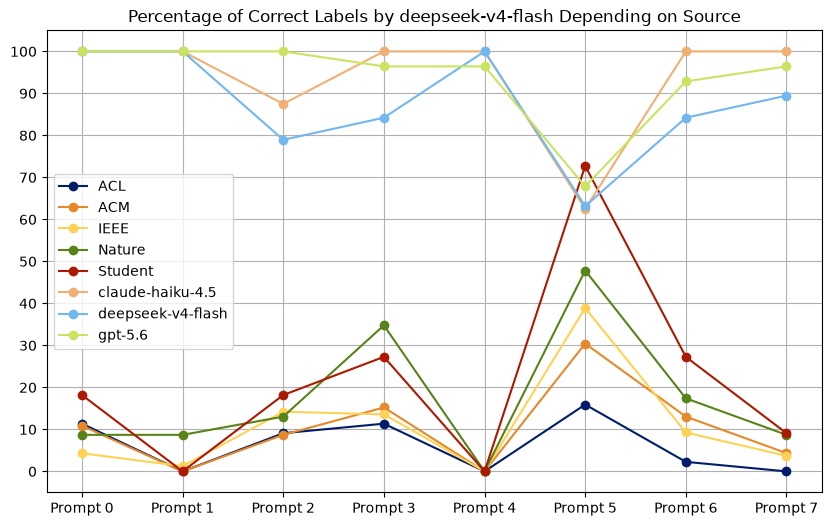

In [144]:
fig1 = prompt_source_gwdg.astype(float).plot(
    y=["ACL", "ACM", "IEEE", "Nature", "Student", "claude-haiku-4.5", "deepseek-v4-flash", "gpt-5.6"], 
    kind="line", 
    title="Percentage of Correct Labels by deepseek-v4-flash Depending on Source", 
    legend=True, 
    color=["#001d6c", "#e7882b", "#ffd256", "#578319", "#AB1900","#F0B075",  "#73B7F0", "#CAE362"], 
    use_index=True,
    grid= True,
    label=["ACL", "ACM", "IEEE", "Nature", "Student", "claude-haiku-4.5", "deepseek-v4-flash", "gpt-5.6"],
    yticks=range(0, 110, 10),
    marker='o',
    figsize=(10, 6)
    )

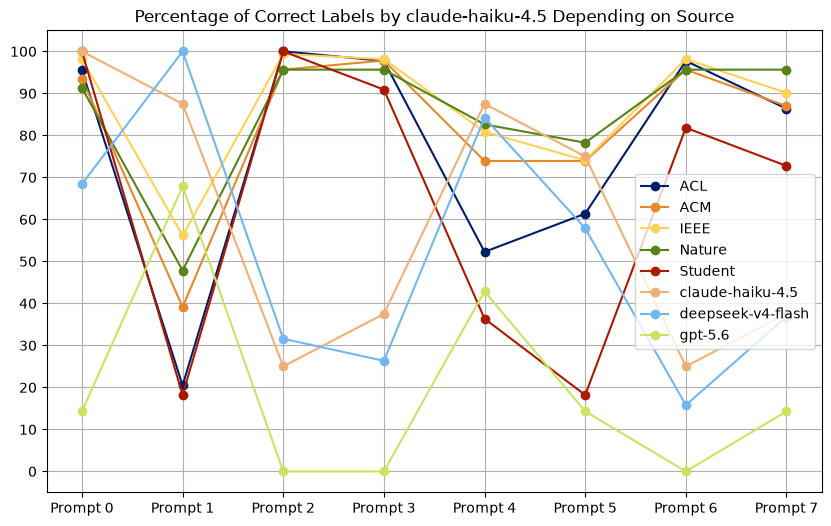

In [145]:
fig2 = prompt_source_anthropic.astype(float).plot(
    y=["ACL", "ACM", "IEEE", "Nature", "Student", "claude-haiku-4.5", "deepseek-v4-flash", "gpt-5.6"], 
    kind="line", 
    title="Percentage of Correct Labels by claude-haiku-4.5 Depending on Source", 
    legend=True, 
    color=["#001d6c", "#e7882b", "#ffd256", "#578319", "#AB1900","#F0B075", "#73B7F0", "#CAE362"], 
    use_index=True,
    grid= True,
    label=["ACL", "ACM", "IEEE", "Nature", "Student", "claude-haiku-4.5", "deepseek-v4-flash", "gpt-5.6"],
    yticks=range(0, 110, 10),
    marker='o',
    figsize=(10, 6)
    )

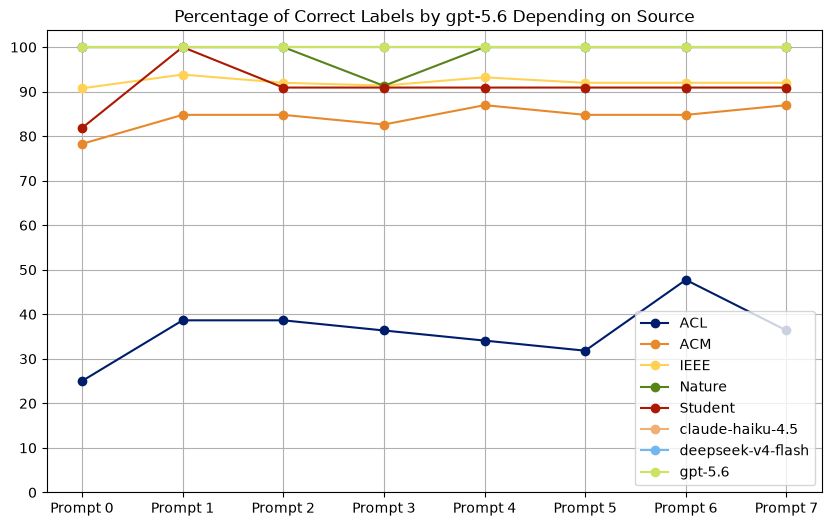

In [146]:
fig2 = prompt_source_openai.astype(float).plot(
    y=["ACL", "ACM", "IEEE", "Nature", "Student", "claude-haiku-4.5", "deepseek-v4-flash", "gpt-5.6"], 
    kind="line", 
    title="Percentage of Correct Labels by gpt-5.6 Depending on Source", 
    legend=True, 
    color=["#001d6c", "#e7882b", "#ffd256", "#578319","#AB1900", "#F0B075", "#73B7F0", "#CAE362"], 
    use_index=True,
    grid= True,
    label=["ACL", "ACM", "IEEE", "Nature", "Student", "claude-haiku-4.5", "deepseek-v4-flash", "gpt-5.6"],
    yticks=range(0, 110, 10),
    marker='o',
    figsize=(10, 6)
    )

In [73]:
prompt_source_openai

,Prompt 0,Prompt 1,Prompt 2,Prompt 3,Prompt 4,Prompt 5,Prompt 6,Prompt 7
ACL,36.36%,36.36%,36.36%,36.36%,36.36%,36.36%,36.36%,36.36%
ACM,86.96%,86.96%,86.96%,86.96%,86.96%,86.96%,86.96%,86.96%
IEEE,91.98%,91.98%,91.98%,91.98%,91.98%,91.98%,91.98%,91.98%
Nature,100.0%,100.0%,100.0%,100.0%,100.0%,100.0%,100.0%,100.0%
Student,90.91%,90.91%,90.91%,90.91%,90.91%,90.91%,90.91%,90.91%
claude-haiku-4.5,100.0%,100.0%,100.0%,100.0%,100.0%,100.0%,100.0%,100.0%
deepseek-v4-flash,100.0%,100.0%,100.0%,100.0%,100.0%,100.0%,100.0%,100.0%
gpt-5.6,100.0%,100.0%,100.0%,100.0%,100.0%,100.0%,100.0%,100.0%


In [ ]:
prompt_source_0 = pd.DataFrame.from_dict(p_dic["Prompt 0"])
prompt_source_0.index = ["ACL", "ACM", "IEEE", "Nature", "Student", "claude-haiku-4.5", "deepseek-v4-flash", "gpt-5.6"]
#prompt_source0 = prompt_source0.transpose()
prompt_source_0

,GWDG,Anthropic,OpenAI
ACL,0.0%,86.36%,36.36%
ACM,4.35%,86.96%,86.96%
IEEE,3.7%,90.12%,91.98%
Nature,8.7%,95.65%,100.0%
Student,9.09%,72.73%,90.91%
claude-haiku-4.5,100.0%,37.5%,100.0%
deepseek-v4-flash,89.47%,36.84%,100.0%
gpt-5.6,96.43%,14.29%,100.0%


In [64]:
complete

GWDG  Anthropic  OpenAI  count GWDG in %  \
             Source 1                                              
Prompt 0     ACL         5.0       42.0    11.0   44.0    11.36%   
             ACM         5.0       43.0    36.0   46.0    10.87%   
             IEEE        7.0      159.0   147.0  162.0     4.32%   
             Nature      2.0       21.0    23.0   23.0      8.7%   
             Student     2.0       11.0     9.0   11.0    18.18%   
...                      ...        ...     ...    ...       ...   
Comparison 2 generated   NaN        NaN     NaN    8.0       NaN   
             generated   NaN        NaN     NaN   19.0       NaN   
             generated   NaN        NaN     NaN   28.0       NaN   
             generated   NaN        NaN     NaN  275.0       NaN   
             generated   NaN        NaN     NaN   55.0       NaN   

                       Anthropic in % OpenAI in %  Checked  Unnamed: 10  
             Source 1                                                    
Prompt 0     ACL               95.45%       25.0%      NaN          NaN  
             ACM               93.48%      78.26%      NaN          NaN  
             IEEE              98.15%      90.74%      NaN          NaN  
             Nature             91.3%      100.0%      NaN          NaN  
             Student           100.0%      81.82%      NaN          NaN  
...                               ...         ...      ...          ...  
Comparison 2 generated            NaN         NaN      5.0     0.625000  
             generated            NaN         NaN     15.0     0.789474  
             generated            NaN         NaN     22.0     0.785714  
             generated            NaN         NaN    200.0     0.727273  
             generated            NaN         NaN     42.0     0.763636  

[102 rows x 9 columns]

In [122]:
def calculate_stats(df,  filename):
    prompts = ["Prompt 0", "Prompt 1", "Prompt 2", "Prompt 3", "Prompt 4", "Prompt 5", "Prompt 6", "Prompt 7"]
    for elem in prompts:
        y_actu = df["Correct"].to_list()
        y_pred = df[elem].to_list()
        cm = ConfusionMatrix(y_actu, y_pred,digit=5)

        with open(filename, "+a", encoding="utf-8") as file:
            cm.print_matrix(file)
            file.write(f"\n\n{cm.stat(summary=True)}\n#########")
            #the saving did not work, so the printed outout was saved manually into the file by copy-pasting

In [123]:
calculate_stats(anthropic_df, "Stats_Anthropic.txt")

Predict             generated           human-written       
Actual
generated           25                  30                  

human-written       10                  276                 


Overall Statistics : 

ACC Macro                                                         0.8827
F1 Macro                                                          0.74399
FPR Macro                                                         0.29021
Kappa                                                             0.4918
NPV Macro                                                         0.80812
Overall ACC                                                       0.8827
PPV Macro                                                         0.80812
SOA1(Landis & Koch)                                               Moderate
TPR Macro                                                         0.70979
Zero-one Loss                                                     40

Class Statistics :

Classes                       

In [124]:
calculate_stats(openai_df, "Stats_OpenAI.txt")

Predict             generated           human-written       nan                 
Actual
generated           55                  0                   0                   

human-written       59                  226                 1                   

nan                 0                   0                   0                   


Overall Statistics : 

ACC Macro                                                         0.8827
F1 Macro                                                          0.51123
FPR Macro                                                         0.06974
Kappa                                                             0.54909
NPV Macro                                                         0.82609
Overall ACC                                                       0.82405
PPV Macro                                                         0.49415
SOA1(Landis & Koch)                                               Moderate
TPR Macro                                         

In [125]:
calculate_stats(gwdg_df, "Stats_GWDG.txt")

Predict             generated           human-written       
Actual
generated           55                  0                   

human-written       265                 21                  


Overall Statistics : 

ACC Macro                                                         0.22287
F1 Macro                                                          0.21507
FPR Macro                                                         0.46329
Kappa                                                             0.02493
NPV Macro                                                         0.58594
Overall ACC                                                       0.22287
PPV Macro                                                         0.58594
SOA1(Landis & Koch)                                               Slight
TPR Macro                                                         0.53671
Zero-one Loss                                                     265

Class Statistics :

Classes                     

Calculating statistical significants between Prompt 0 and the Comparison Prompts

In [126]:
#checking for normal distribution
shapiro(comparison["Checked"].to_list())
#smaller then p-value -> not normal-distributed

ShapiroResult(statistic=np.float64(0.4212243941204672), pvalue=np.float64(1.2928603105400117e-31))

In [46]:
shapiro(prompt_0_checked["OpenAI"].to_list())

ShapiroResult(statistic=np.float64(0.4612362381598454), pvalue=np.float64(9.26558490170413e-31))

In [47]:
shapiro(comparison2["Checked"].to_list())

ShapiroResult(statistic=np.float64(0.5450969395439231), pvalue=np.float64(8.669016203268194e-29))

In [48]:
shapiro(prompt_0_checked["GWDG"].to_list())

ShapiroResult(statistic=np.float64(0.5135544514645405), pvalue=np.float64(1.4627784161151697e-29))

H0: m1 - m2 <= 0, m1 <= m2
wenn p<= 0.05 -> The first population medians is significantly greater second.

In [129]:
#Basis Prompt
both = stats.wilcoxon(comparison["Checked"].to_list(), prompt_0_checked["OpenAI"].to_list())
great = stats.wilcoxon(comparison["Checked"].to_list(), prompt_0_checked["OpenAI"].to_list(), alternative="greater")
low = stats.wilcoxon(comparison["Checked"].to_list(), prompt_0_checked["OpenAI"].to_list(), alternative="less")
print(f"Two-tailed: {both.pvalue}\nGreater: {great.pvalue}\nLesser: {low.pvalue}")

Two-tailed: 0.003892417122778628
Greater: 0.001946208561389314
Lesser: 0.9980537914386107


In [128]:
#Basis Prompt
both = stats.wilcoxon(comparison2["Checked"].to_list(), prompt_0_checked["GWDG"].to_list())
great = stats.wilcoxon(comparison2["Checked"].to_list(), prompt_0_checked["GWDG"].to_list(), alternative="greater")
low = stats.wilcoxon(comparison2["Checked"].to_list(), prompt_0_checked["GWDG"].to_list(), alternative="less")
print(f"Two-tailed: {both.pvalue}\nGreater: {great.pvalue}\nLesser: {low.pvalue}")

Two-tailed: 2.94429458607757e-33
Greater: 1.472147293038785e-33
Lesser: 1.0


In [133]:
#Best Prompt -> Prompt 1
both = stats.wilcoxon(comparison["Checked"].to_list(), prompt_1_checked["OpenAI"].to_list())
great = stats.wilcoxon(comparison["Checked"].to_list(), prompt_1_checked["OpenAI"].to_list(), alternative="greater")
low = stats.wilcoxon(comparison["Checked"].to_list(), prompt_1_checked["OpenAI"].to_list(), alternative="less")
print(f"Two-tailed: {both.pvalue}\nGreater: {great.pvalue}\nLesser: {low.pvalue}")

Two-tailed: 0.057779571123597245
Greater: 0.9711102144382013
Lesser: 0.028889785561798623


In [131]:
#Best Prompt -> Prompt 6
both = stats.wilcoxon(comparison["Checked"].to_list(), prompt_6_checked["OpenAI"].to_list())
great = stats.wilcoxon(comparison["Checked"].to_list(), prompt_6_checked["OpenAI"].to_list(), alternative="greater")
low = stats.wilcoxon(comparison["Checked"].to_list(), prompt_6_checked["OpenAI"].to_list(), alternative="less")
print(f"Two-tailed: {both.pvalue}\nGreater: {great.pvalue}\nLesser: {low.pvalue}")

Two-tailed: 0.057779571123597245
Greater: 0.9711102144382013
Lesser: 0.028889785561798623


In [132]:
#Best Prompt -> Prompt 5
both = stats.wilcoxon(comparison2["Checked"].to_list(), prompt_5_checked["GWDG"].to_list())
great = stats.wilcoxon(comparison2["Checked"].to_list(), prompt_5_checked["GWDG"].to_list(), alternative="greater")
low = stats.wilcoxon(comparison2["Checked"].to_list(), prompt_5_checked["GWDG"].to_list(), alternative="less")
print(f"Two-tailed: {both.pvalue}\nGreater: {great.pvalue}\nLesser: {low.pvalue}")

Two-tailed: 3.3458311503921897e-19
Greater: 1.6729155751960949e-19
Lesser: 1.0


In [150]:
openai_df.tail(10)

,Unnamed: 0.1,File,Prompt 0,Prompt 1,Prompt 2,Prompt 3,Prompt 4,Prompt 5,Prompt 6,Prompt 7,Correct
331,331,401.md,human-written,human-written,human-written,human-written,human-written,human-written,human-written,human-written,human-written
332,332,402.md,human-written,human-written,human-written,human-written,human-written,human-written,human-written,human-written,human-written
333,333,403.md,human-written,human-written,human-written,human-written,human-written,human-written,human-written,human-written,human-written
334,334,404.md,generated,human-written,generated,generated,generated,generated,generated,generated,human-written
335,335,405.md,generated,human-written,human-written,human-written,human-written,human-written,human-written,human-written,human-written
336,336,406.md,human-written,human-written,human-written,human-written,human-written,human-written,human-written,human-written,human-written
337,337,407.md,human-written,human-written,human-written,human-written,human-written,human-written,human-written,human-written,human-written
338,338,408.md,human-written,human-written,human-written,human-written,human-written,human-written,human-written,human-written,human-written
339,339,409.md,human-written,human-written,human-written,human-written,human-written,human-written,human-written,human-written,human-written
340,340,410.md,human-written,human-written,human-written,human-written,human-written,human-written,human-written,human-written,human-written


In [149]:
kom_key

,Original,New
0,22-07-22_Essay.md,400.md
1,BA_Vong.md,401.md
2,do smart cities create accessibility for peopl...,402.md
3,Dokumentation_Suelzen.md,403.md
4,Konsti_1.md,404.md
5,Konsti_2.md,405.md
6,Konsti_2_2.md,406.md
7,petz_essay.md,407.md
8,Suelzen_TermPaper_19th-centuryEnglish.md,408.md
9,Sülzen_SoSe2023_Dictionaries.md,409.md
